# MMA3001 — Stage 1: NASA C-MAPSS FD001 Exploratory Data Analysis

**Project:** Predicting Remaining Useful Life (RUL) of Turbofan Engines Using Machine Learning  
**Dataset:** NASA C-MAPSS **FD001 only**  
**Objective:** Verify data quality, visualise engine degradation, identify promising model inputs and document appropriate preprocessing decisions.

**Important:** This notebook performs exploratory analysis on the **training data**. The supplied `RUL_FD001.txt` labels are reserved for the final evaluation stage; they are **not used to choose features or models**.

Source: [NASA Prognostics Center of Excellence Dataset Repository](https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/). Please also consult `data/readme.txt`.

## 1 — Imports and file loading

Keep this notebook inside `MMA3001_FD001_Stage1/`, next to the `data/` folder. Run cells in order. Only `numpy`, `pandas`, `matplotlib` and Jupyter are required.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Robust to launching Jupyter from the project folder or its parent.
BASE = Path.cwd()
if not (BASE / 'data' / 'train_FD001.txt').exists():
    BASE = BASE / 'MMA3001_FD001_Stage1'
DATA = BASE / 'data'
FIGURES = BASE / 'figures'
FIGURES.mkdir(exist_ok=True, parents=True)
assert (DATA / 'train_FD001.txt').exists(), f'Cannot find FD001 files in {DATA}'

cols = ['engine_id', 'cycle'] + [f'setting_{i}' for i in range(1, 4)] + [f'sensor_{i}' for i in range(1, 22)]
train = pd.read_csv(DATA / 'train_FD001.txt', sep=r'\s+', header=None, names=cols)
test = pd.read_csv(DATA / 'test_FD001.txt', sep=r'\s+', header=None, names=cols)
sensors = [f'sensor_{i}' for i in range(1, 22)]

print('Train shape:', train.shape, '| Test shape:', test.shape)
print('Unique engines (train/test):', train.engine_id.nunique(), '/', test.engine_id.nunique())
display(train.head())

Train shape: (20631, 26) | Test shape: (13096, 26)
Unique engines (train/test): 100 / 100


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 2 — Data quality checks

Check missing values, duplicate `(engine_id, cycle)` records, sequential cycles and per-engine history lengths. Note that test histories deliberately stop **before failure**; do **not** treat their last observed cycle as failure.

In [2]:
def audit(df, name):
    missing = int(df.isna().sum().sum())
    duplicates = int(df.duplicated(subset=['engine_id', 'cycle']).sum())
    counts = df.groupby('engine_id').size()
    consecutive = all(
        np.array_equal(g['cycle'].to_numpy(), np.arange(1, len(g) + 1))
        for _, g in df.groupby('engine_id', sort=False)
    )
    print(f'{name}: {len(df):,} rows; {df.engine_id.nunique()} engines; '
          f'{missing} missing cells; {duplicates} duplicate engine/cycles; '
          f'sequential cycles: {consecutive}')
    print(f'  Observed cycles/engine: min {counts.min()}, median {counts.median():.1f}, max {counts.max()}')
    return counts

train_lengths = audit(train, 'TRAIN')
test_lengths = audit(test, 'TEST')

TRAIN: 20,631 rows; 100 engines; 0 missing cells; 0 duplicate engine/cycles; sequential cycles: True
  Observed cycles/engine: min 128, median 199.0, max 362
TEST: 13,096 rows; 100 engines; 0 missing cells; 0 duplicate engine/cycles; sequential cycles: True
  Observed cycles/engine: min 31, median 133.5, max 303


## 3 — Engine life distribution

Each FD001 training trajectory runs to failure. Thus the maximum cycle recorded for each training engine is its **failure cycle**. We can visualise variation in simulated engine lifetimes.

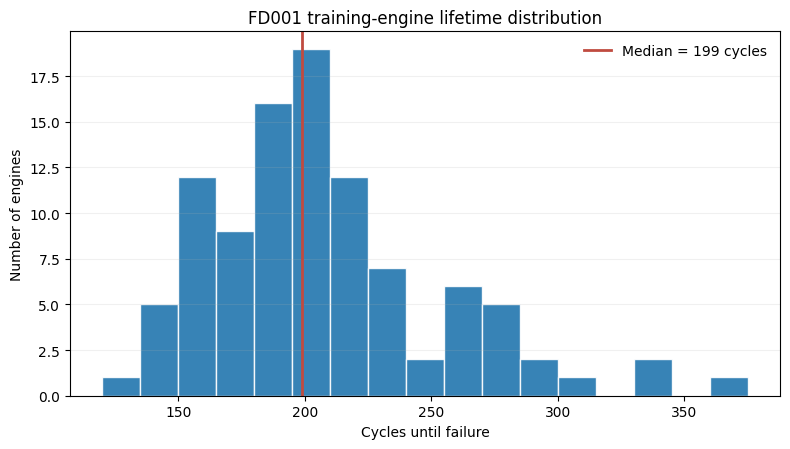

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000


In [3]:
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hist(train_lengths, bins=np.arange(120, 381, 15), color='#2176ae', edgecolor='white', alpha=.9)
ax.axvline(train_lengths.median(), color='#c04b40', lw=2,
           label=f'Median = {train_lengths.median():.0f} cycles')
ax.set(title='FD001 training-engine lifetime distribution', xlabel='Cycles until failure', ylabel='Number of engines')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=.18)
fig.tight_layout()
fig.savefig(FIGURES / '01_engine_lifetime_distribution.png', dpi=180)
plt.show()
print(train_lengths.describe().to_string())

## 4 — Construct training RUL target

For each *training* engine, `RUL = its failure cycle − current cycle`.

The final training row for each engine has RUL = 0. Testing engines have truncated histories and **must use** NASA's provided RUL labels in the later evaluation stage.

This notebook uses **uncapped** RUL to represent the target without introducing a modelling assumption.

In [4]:
failure_cycles = train.groupby('engine_id')['cycle'].max()
train['RUL'] = train['engine_id'].map(failure_cycles) - train['cycle']
assert (train.groupby('engine_id')['RUL'].min() == 0).all()
print(train[['engine_id', 'cycle', 'RUL']].head(7).to_string(index=False))
print('RUL range:', int(train.RUL.min()), 'to', int(train.RUL.max()), 'cycles')

 engine_id  cycle  RUL
         1      1  191
         1      2  190
         1      3  189
         1      4  188
         1      5  187
         1      6  186
         1      7  185
RUL range: 0 to 361 cycles


## 5 — Example degradation patterns

Plot selected sensors for three example engines. The sensors have different units and scales, so **the curves below are converted to z-scores for visualization only**. This is not the fitted feature scaler for machine learning.

Increasing sensor values are not necessarily 'better' or 'worse' by themselves; the important point is the *direction and consistency of change as failure approaches*.

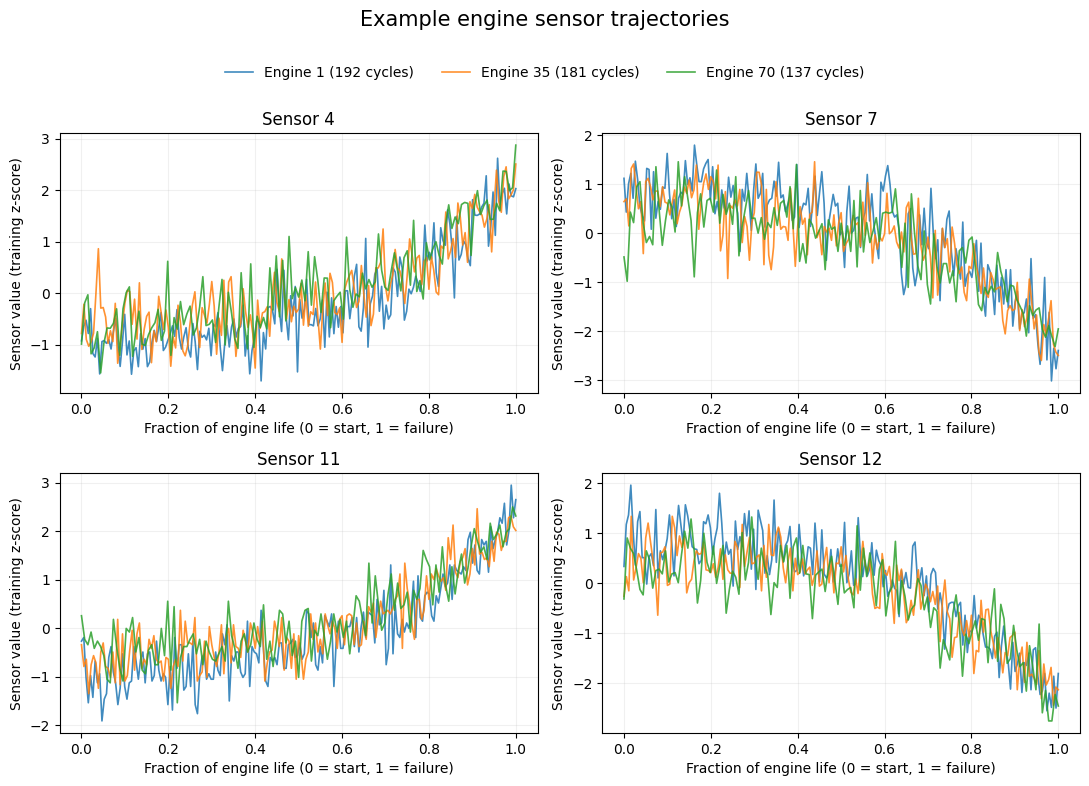

In [5]:
examples = [1, 35, 70]
show_sensors = ['sensor_4', 'sensor_7', 'sensor_11', 'sensor_12']
fig, axes = plt.subplots(2, 2, figsize=(11, 7.3), sharex=False)
for ax, sensor in zip(axes.flat, show_sensors):
    mu, std = train[sensor].mean(), train[sensor].std()
    for engine in examples:
        g = train.loc[train.engine_id == engine]
        normalized_life = (g.cycle - 1) / (g.cycle.max() - 1)
        ax.plot(normalized_life, (g[sensor] - mu) / std, lw=1.2, alpha=.85,
                label=f'Engine {engine} ({g.cycle.max()} cycles)')
    ax.set(title=sensor.replace('_', ' ').title(), xlabel='Fraction of engine life (0 = start, 1 = failure)',
           ylabel='Sensor value (training z-score)')
    ax.grid(alpha=.18)
handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False, bbox_to_anchor=(.5, 1.01))
fig.suptitle('Example engine sensor trajectories', y=1.07, fontsize=15)
fig.tight_layout()
fig.savefig(FIGURES / '02_example_sensor_trajectories.png', dpi=180, bbox_inches='tight')
plt.show()

## 6 — Identify uninformative sensors

Columns with exactly **one unique value** provide no variation for learning. `sensor_6` contains only two very close values and is another potential low-information feature. We will examine it further during preprocessing rather than arbitrarily removing it without documentation.

`setting_3` is also exactly constant in FD001. `engine_id` is an identifier for grouping and **not a predictor**.

In [6]:
summary = pd.DataFrame({
    'unique_values': train[sensors].nunique(),
    'min': train[sensors].min(),
    'max': train[sensors].max(),
    'std': train[sensors].std(),
})
summary.index.name = 'sensor'
summary['constant'] = summary.unique_values == 1
summary['range'] = summary['max'] - summary['min']
constant_sensors = summary.index[summary.constant].tolist()
near_constant_sensors = summary.index[(summary.unique_values <= 2) & (~summary.constant)].tolist()
print('Constant sensors:', constant_sensors)
print('Near-constant sensors (2 distinct values):', near_constant_sensors)
print('Constant operating settings:', [c for c in ['setting_1','setting_2','setting_3'] if train[c].nunique() == 1])
display(summary.round(5))
summary.to_csv(FIGURES / 'sensor_variability_summary.csv')

Constant sensors: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Near-constant sensors (2 distinct values): ['sensor_6']
Constant operating settings: ['setting_3']


,unique_values,min,max,std,constant,range
sensor,,,,,,
sensor_1,1,518.6700,518.6700,0.00000,True,0.0000
sensor_2,310,641.2100,644.5300,0.50005,False,3.3200
sensor_3,3012,1571.0400,1616.9100,6.13115,False,45.8700
sensor_4,4051,1382.2500,1441.4900,9.00060,False,59.2400
sensor_5,1,14.6200,14.6200,0.00000,True,0.0000
sensor_6,2,21.6000,21.6100,0.00139,False,0.0100
sensor_7,513,549.8500,556.0600,0.88509,False,6.2100
sensor_8,53,2387.9000,2388.5600,0.07099,False,0.6600
sensor_9,6403,9021.7300,9244.5900,22.08288,False,222.8600


## 7 — Sensor–RUL relationships

We calculate **Pearson correlation** between each sensor and RUL on the training histories. Values near ±1 indicate a strong linear association, while values near 0 suggest a weak *pooled* linear association, **not necessarily an absence of predictive information**.

**Interpretation caution:** RUL is generated from elapsed cycles. Correlation can reflect shared time trends, multiple sensors can be redundant, and pooled associations do not prove causation. Final feature decisions require validation on separate engines.

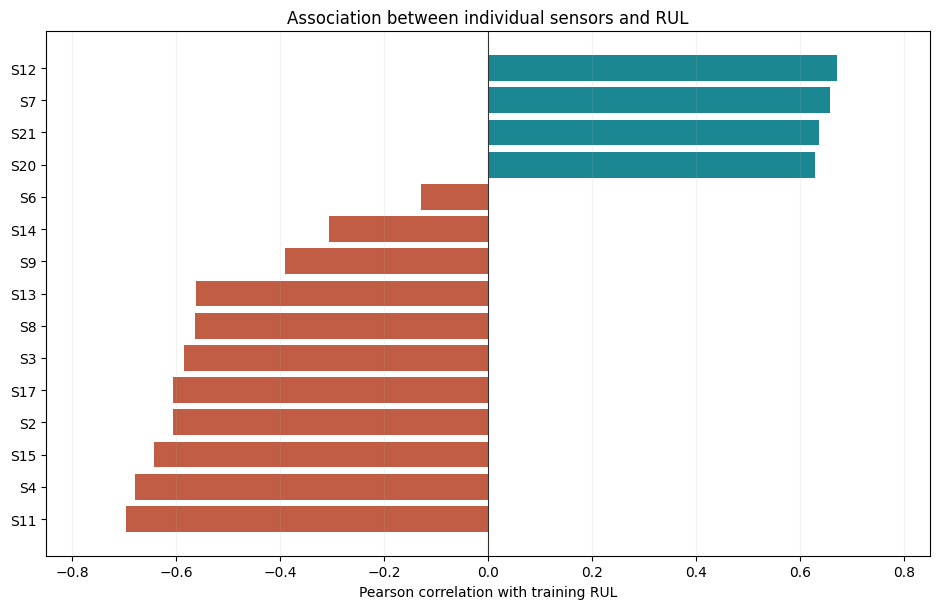

Strongest absolute pooled linear associations:
sensor_11    0.696
sensor_4     0.679
sensor_12    0.672
sensor_7     0.657
sensor_15    0.643
sensor_21    0.636
sensor_20    0.629
sensor_2     0.606
sensor_17    0.606
sensor_3     0.585


In [7]:
varying = [s for s in sensors if train[s].nunique() > 1]
pearson = train[varying].corrwith(train['RUL']).dropna().sort_values()
fig, ax = plt.subplots(figsize=(9.5, 6.2))
bar_colors = np.where(pearson.values >= 0, '#1b8793', '#c05d44')
ax.barh(pearson.index.str.replace('sensor_', 'S'), pearson.values, color=bar_colors)
ax.axvline(0, color='#333333', lw=.8)
ax.set(xlabel='Pearson correlation with training RUL', title='Association between individual sensors and RUL', xlim=(-.85,.85))
ax.grid(axis='x', alpha=.16)
fig.tight_layout()
fig.savefig(FIGURES / '03_sensor_RUL_correlations.png', dpi=180)
plt.show()
print('Strongest absolute pooled linear associations:')
print(pearson.abs().sort_values(ascending=False).head(10).round(3).to_string())

## 8 — Correlation and redundancy between candidate sensors

Highly correlated sensors may provide partly overlapping information. A correlation heatmap helps identify multicollinearity, which is especially relevant when interpreting linear-regression coefficients.

These candidates are chosen as an *initial shortlist for further testing*, not as the definitive features.

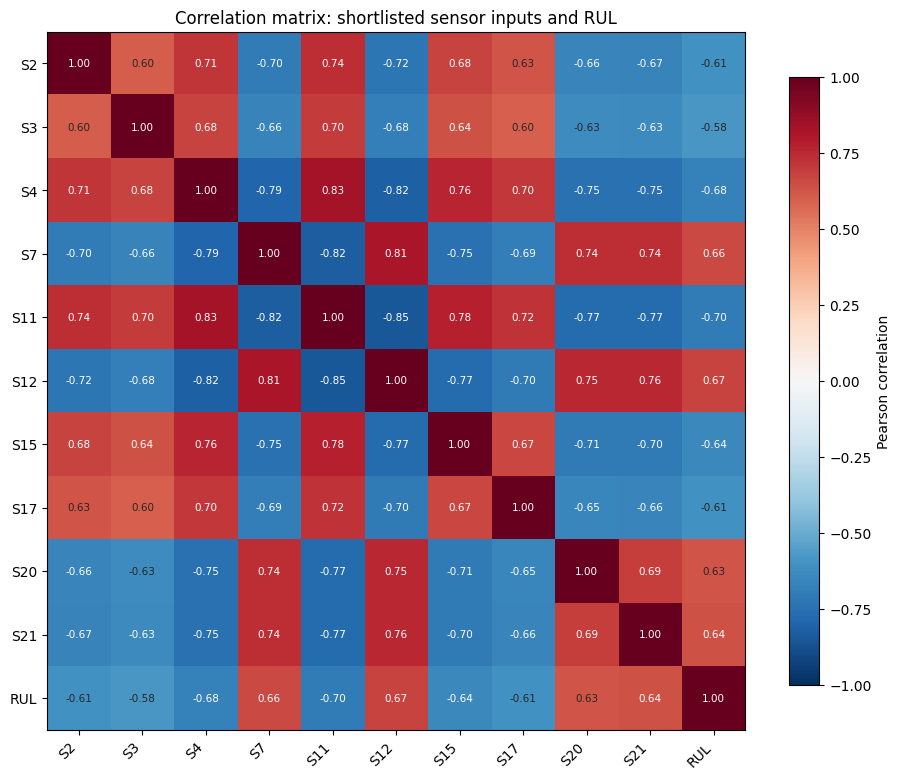

In [8]:
candidates = ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_11', 'sensor_12',
              'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
mat = train[candidates + ['RUL']].corr()
fig, ax = plt.subplots(figsize=(9.4, 8.1))
im = ax.imshow(mat.to_numpy(), vmin=-1, vmax=1, cmap='RdBu_r')
labels = [x.replace('sensor_', 'S') for x in mat.columns]
ax.set_xticks(range(len(labels)), labels=labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels)), labels=labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = mat.iloc[i,j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7.5,
                color='white' if abs(v) > .63 else '#262626')
ax.set_title('Correlation matrix: shortlisted sensor inputs and RUL')
fig.colorbar(im, ax=ax, label='Pearson correlation', shrink=.8)
fig.tight_layout()
fig.savefig(FIGURES / '04_candidate_sensor_correlation_matrix.png', dpi=180)
plt.show()

## 9 — Stage 1 findings and Stage 2 decisions

**Verified facts (FD001 only):**

- **20,631** train rows from **100** complete engine histories; **13,096** test rows from **100** truncated engine histories.
- **26** raw columns: engine ID, cycle, 3 operational settings and 21 sensors.
- No missing values or duplicate engine-cycle keys in either file.
- Training-engine lifetimes range from **128 to 362 cycles** (median **199**).
- Exactly constant sensors: **S1, S5, S10, S16, S18, S19**; exactly constant operating setting: **setting 3**.
- **S6** has only two unique values and is a plausible low-information feature.
- **S11, S4, S12 and S7** have comparatively strong pooled linear relationships with RUL. The direction of the trend differs by sensor.

**Proposed engineering-informed starting feature set:** Keep the non-constant sensors except S6 for a provisional baseline, include `cycle` (with an ablation test), and exclude `engine_id` from features. Consider operating settings 1 and 2 only if validation shows they help. Investigate a smaller candidate set and rolling/trend features as controlled experiments.

**Safeguards for Stage 2 and later:**

1. Split training/validation **by entire engine**, never by rows.
2. Fit scaling, feature selection and any learned transformations on the **training fold only**.
3. Reserve test RUL labels for **one final evaluation**, not exploratory tuning.
4. Evaluate final predictions at the **last available cycle** of each held-out test engine; test histories do **not** end at failure.
5. Include a simple **cycle-only baseline** and report whether the sensor channels actually improve RUL prediction. A naive `RUL = constant − cycle` can otherwise make sensor value difficult to judge.

**Scope note:** FD001 uses simulated single-condition high-pressure compressor degradation. Performance here cannot be directly claimed for real A320 engines or other failure modes.

## Reference

A. Saxena, K. Goebel, D. Simon and N. Eklund, “Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation,” *1st International Conference on Prognostics and Health Management*, Denver, 2008. Refer to the PDF bundled with the original NASA download.

**Stage 1 completed:** Proceed to Stage 2 preprocessing only after reviewing feature-selection assumptions and preserving the untouched test labels.